# Understanding U.S. Airline Delays: Causes, Trends and Predictive Insights ✈️

#### Business Problem
Flight delays create significant operational challenges for airlines, airports, and passengers. Delays can lead to increased costs, missed connections, reduced customer satisfaction, and disruptions throughout the transportation network. Understanding the causes and patterns of airline delays can help airlines improve scheduling decisions, resource allocation, and operational efficiency.

**Research Question**: What factors contribute most to airline delays in the United States, and how do their impacts vary across airlines and airports?

**Objectives**:

- Identify airlines with the highest delay rates
- Determine major causes of delays
- Explore airport-level delay patterns
- Examine yearly and seasonal trends
- Build a predictive model for airline delays

**Dataset**: U.S. Airline Delay Statistics (Kaggle). Each row is one airline at one airport for one month.

> **Note:** the data only contains **December 2019** and **December 2020**, so I compared those two Decembers instead of looking at full-year seasonal trends.

## Import Libraries

In [18]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Plot settings
plt.style.use("seaborn-v0_8")
sns.set_palette("Set2")

# Display settings
pd.set_option('display.max_columns', None)

## Load and Inspect Data

In [64]:
# Loading dataset
df = pd.read_csv("airline_delay.csv")
display(df.head())

# Data info & checking for missing values
print("Dataset shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Airlines:", df["carrier"].nunique(), ", Airports:", df["airport"].nunique())

,year,month,carrier,carrier_name,airport,airport_name,arr_flights,arr_del15,carrier_ct,weather_ct,nas_ct,security_ct,late_aircraft_ct,arr_cancelled,arr_diverted,arr_delay,carrier_delay,weather_delay,nas_delay,security_delay,late_aircraft_delay
0,2020,12,9E,Endeavor Air Inc.,ABE,"Allentown/Bethlehem/Easton, PA: Lehigh Valley ...",44.0,3.0,1.63,0.0,0.12,0.0,1.25,0.0,1.0,89.0,56.0,0.0,3.0,0.0,30.0
1,2020,12,9E,Endeavor Air Inc.,ABY,"Albany, GA: Southwest Georgia Regional",90.0,1.0,0.96,0.0,0.04,0.0,0.00,0.0,0.0,23.0,22.0,0.0,1.0,0.0,0.0
2,2020,12,9E,Endeavor Air Inc.,AEX,"Alexandria, LA: Alexandria International",88.0,8.0,5.75,0.0,1.60,0.0,0.65,0.0,1.0,338.0,265.0,0.0,45.0,0.0,28.0
3,2020,12,9E,Endeavor Air Inc.,AGS,"Augusta, GA: Augusta Regional at Bush Field",184.0,9.0,4.17,0.0,1.83,0.0,3.00,0.0,0.0,508.0,192.0,0.0,92.0,0.0,224.0
4,2020,12,9E,Endeavor Air Inc.,ALB,"Albany, NY: Albany International",76.0,11.0,4.78,0.0,5.22,0.0,1.00,1.0,0.0,692.0,398.0,0.0,178.0,0.0,116.0


Dataset shape: (3351, 21)
Missing values: 120
Airlines: 17 , Airports: 360


This dataset contains 3,351 observations across 21 columns. There are 17 airlines and 360 airports in the dataset.
There are 120 missing values. 

## Data Cleaning

In [66]:
# Which rows have missing values?
missing_rows = df[df.isnull().any(axis=1)]
print("Rows with missing values:", len(missing_rows))
print("Missing cells in each of those rows:", missing_rows.isnull().sum(axis=1).unique())

Rows with missing values: 8
Missing cells in each of those rows: [19]


The 120 missing values come from just **8 rows that are completely empty**. These are airline–airport pairs with no reported data.

In [67]:
df = df.dropna().copy()
print("Rows after cleaning:", len(df))
print("Missing values:", df.isnull().sum().sum())

Rows after cleaning: 3343
Missing values: 0


After removing records with no reported data, there are zero missing values. 

## Create New Columns

In [81]:
# Delay rate
df["delay_rate"] = (df["arr_del15"] / df["arr_flights"]) * 100

# Cancellation rate 
df['cancel_rate'] = (df['arr_cancelled'] / df['arr_flights']) * 100

# Diversion rate 
df['diversion_rate'] = (df['arr_diverted'] / df['arr_flights']) * 100

# Total delay minutes 
cause_minutes = ["carrier_delay", "weather_delay", "nas_delay", "security_delay", "late_aircraft_delay"]
cause_counts  = ["carrier_ct", "weather_ct", "nas_ct", "security_ct", "late_aircraft_ct"]
df["total_delay_minutes"] = df[cause_minutes].sum(axis=1)

# Month name 
month_map = {
    1:"Jan", 2:"Feb", 3:"Mar", 4:"Apr",
    5:"May", 6:"Jun", 7:"Jul", 8:"Aug",
    9:"Sep", 10:"Oct", 11:"Nov", 12:"Dec"
}

df['month_name'] = df['month'].map(month_map)

# A helper for fair (flight-weighted) delay rates
def group_rate(data, by):
    g = data.groupby(by).agg(flights=("arr_flights", "sum"), delayed=("arr_del15", "sum"),
                             cancelled=("arr_cancelled", "sum"))
    g["delay_rate"]  = g["delayed"] / g["flights"] * 100
    g["cancel_rate"] = g["cancelled"] / g["flights"] * 100
    return g

## Exploratory Data Analysis (EDA)

### Distribution of delay rates

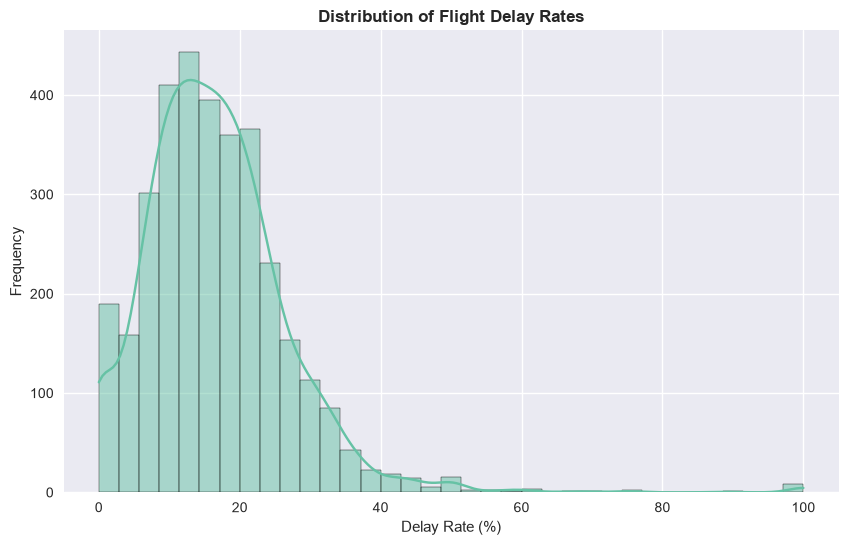

Median delay rate: 16.1 %
Overall (weighted) delay rate: 17.1 %


In [76]:
plt.figure(figsize=(10,6))

sns.histplot(
    df['delay_rate'],
    bins=35,
    kde=True
)

plt.title("Distribution of Flight Delay Rates", fontweight='bold')
plt.xlabel("Delay Rate (%)")
plt.ylabel("Frequency")
plt.show()

print("Median delay rate:", round(df.loc[df["arr_flights"] >= 25, "delay_rate"].median(), 1), "%")
print("Overall (weighted) delay rate:", round(df["arr_del15"].sum() / df["arr_flights"].sum() * 100, 1), "%")

**Interpretation:** A typical airline–airport record has about **16%** of flights arriving late. Most records fall between about 10% and 22%, with a smaller number of very delayed cases on the right.

### What causes the most delays? 

,share_of_delay_minutes_%,avg_minutes_per_delay
Late aircraft,37.7,73.2
Carrier,34.3,71.3
NAS (airport / air traffic),22.5,46.3
Weather,5.3,123.1
Security,0.2,39.3


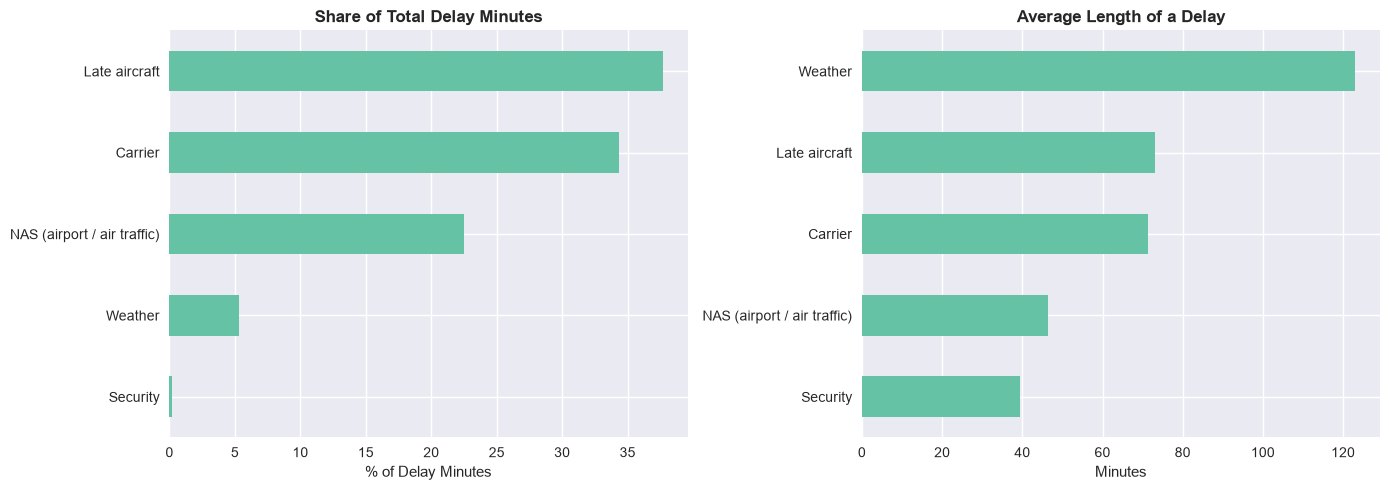

In [80]:
labels = ["Carrier", "Weather", "NAS (airport / air traffic)", "Security", "Late aircraft"]

minutes = pd.Series(df[cause_minutes].sum().values, index=labels)
counts  = pd.Series(df[cause_counts].sum().values, index=labels)
cause_table = pd.DataFrame({
    "share_of_delay_minutes_%": minutes / minutes.sum() * 100,
    "avg_minutes_per_delay": minutes / counts,
}).sort_values("share_of_delay_minutes_%", ascending=False)
display(cause_table.round(1))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
cause_table["share_of_delay_minutes_%"].sort_values().plot(kind="barh", ax=axes[0])
axes[0].set_title("Share of Total Delay Minutes", fontweight="bold")
axes[0].set_xlabel("% of Delay Minutes")
cause_table["avg_minutes_per_delay"].sort_values().plot(kind="barh", ax=axes[1])
axes[1].set_title("Average Length of a Delay", fontweight="bold")
axes[1].set_xlabel("Minutes")
plt.tight_layout()
plt.show()

**Interpretation:** 
- **Late aircraft (37.7%) and carrier problems (34.3%)** together account for about 72% of delay minutes. NAS (airport and air traffic control) adds 22.5%.
- **Are delays mostly operational?** Largely yes. Carrier delays are within the airline's control, and late-aircraft delays are knock-on effects of earlier delays that a tight schedule lets spread.
- **Is weather the main issue?** No. Weather causes only 5.3% of delay minutes, although weather delays are the longest (about 123 minutes each vs. 39 to 73 for other causes).
- **Are downstream delays important?** Yes. Late aircraft is the single largest cause: one late flight early in the day can delay the rest of that plane's flights.

### Airlines with highest delay rates

I compared each airline in December 2019 and December 2020 separately. 

year,2019,2020
carrier_name,,
JetBlue Airways,32.2,20.4
Allegiant Air,25.5,14.7
Alaska Airlines Inc.,24.9,7.5
ExpressJet Airlines LLC,24.0,NaN
Mesa Airlines Inc.,24.0,15.8
PSA Airlines Inc.,23.8,9.7
Frontier Airlines Inc.,23.5,10.5
Southwest Airlines Co.,21.0,10.2
Republic Airline,20.9,8.9


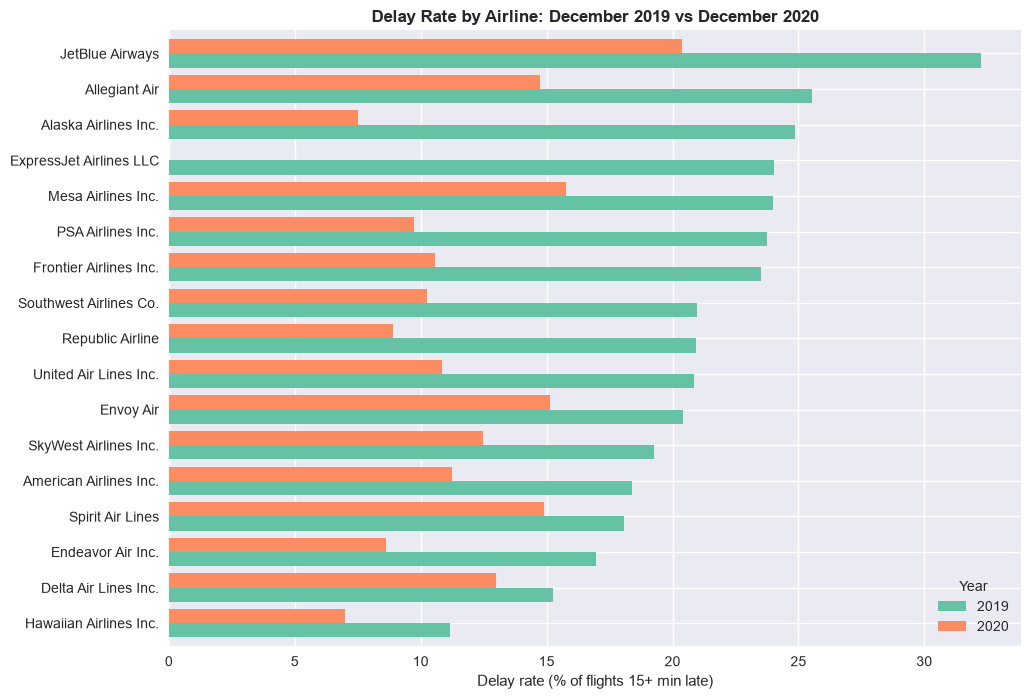

In [83]:
carrier_year = group_rate(df, ["carrier_name", "year"]).reset_index()
carrier_rates = carrier_year.pivot(index="carrier_name", columns="year", values="delay_rate")
carrier_rates = carrier_rates.sort_values(2019, ascending=False)
display(carrier_rates.round(1))

carrier_rates.sort_values(2019).plot(kind="barh", figsize=(11, 8), width=0.8)
plt.title("Delay Rate by Airline: December 2019 vs December 2020", fontweight="bold")
plt.xlabel("Delay rate (% of flights 15+ min late)")
plt.ylabel("")
plt.legend(title="Year")
plt.show()

**Interpretation**
- **JetBlue has the highest delay rate in both years** (32.2% in 2019 and 20.4% in 2020). It flies a lot into busy airports such as Boston, JFK and Fort Lauderdale, which may contribute, though this data can't prove it.
- **Hawaiian Airlines and Delta** had the lowest delay rates in 2019.
- **Every airline improved in 2020**, but not equally. Alaska improved the most (24.9% to 7.5%) while Delta improved the least (15.3% to 13.0%).
- **ExpressJet** appears only in 2019 because it stopped flying in 2020.
- Rankings are a snapshot of two Decembers, not a permanent score for each airline.

### Airports with highest delay rates

Airports included: 83


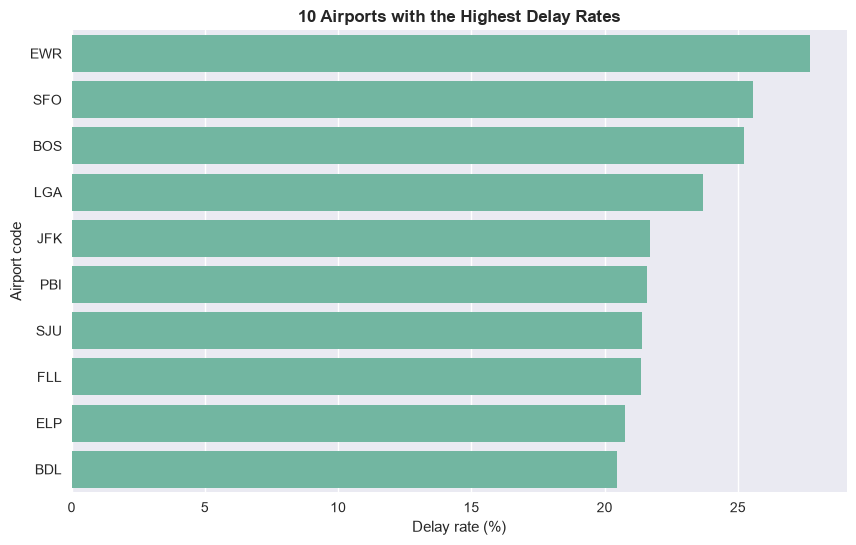

Lowest delay rates:


,flights,delay_rate
airport,,
MDW,11041.0,13.3
OGG,3970.0,12.3
ATL,55438.0,11.8
HNL,7554.0,11.1
KOA,2249.0,10.9


In [84]:
airport_rates = group_rate(df, "airport")
airport_rates = airport_rates[airport_rates["flights"] >= 2000].sort_values("delay_rate", ascending=False)
print("Airports included:", len(airport_rates))

top10 = airport_rates.head(10)
plt.figure(figsize=(10, 6))
sns.barplot(x=top10["delay_rate"], y=top10.index)
plt.title("10 Airports with the Highest Delay Rates", fontweight="bold")
plt.xlabel("Delay rate (%)")
plt.ylabel("Airport code")
plt.show()

print("Lowest delay rates:")
display(airport_rates.tail(5)[["flights", "delay_rate"]].round(1))

In [86]:
# Do airport rankings stay the same from one year to the next?

airport_year = group_rate(df, ["airport", "year"]).reset_index()
airport_year = airport_year[airport_year["flights"] >= 1000]
by_year = airport_year.pivot(index="airport", columns="year", values="delay_rate").dropna()
print("Correlation between 2019 and 2020 airport delay rates:", round(by_year[2019].corr(by_year[2020]), 2))
by_year.sort_values(2019, ascending=False).head(5).round(1)

Correlation between 2019 and 2020 airport delay rates: 0.09


year,2019,2020
airport,,
EWR,34.9,11.6
SFO,33.4,7.8
BOS,29.2,14.9
LGA,27.5,10.2
SJU,26.8,14.8


**Interpretation**
- **Newark (27.7%), San Francisco (25.6%), Boston (25.2%) and LaGuardia (23.7%)** have the highest delay rates. These are busy airports with limited capacity. The best are Hawaii airports (Kona, Honolulu) and **Atlanta (11.8%)**, which is notable because Atlanta handles far more flights than most airports.
- **Rankings were not consistent between years.** The correlation between 2019 and 2020 airport delay rates is close to zero. For example, San Francisco was among the worst airports in 2019 but among the best in 2020.
- So airport delays in this data are strongly affected by what happened in a particular month. With only two Decembers, I can't say that an airport is *always* slow.

### Covid-19 Impact Analysis

,flights,delay_rate,cancel_rate,diversion_rate
year,,,,
2019,625763.0,20.29,0.93,0.22
2020,371357.0,11.72,1.04,0.15


Change in flights: -40.7%


year,2019,2020
Carrier,5.83,4.64
Weather,0.51,0.45
NAS (airport / air traffic),6.18,4.16
Security,0.04,0.05
Late aircraft,7.73,2.43


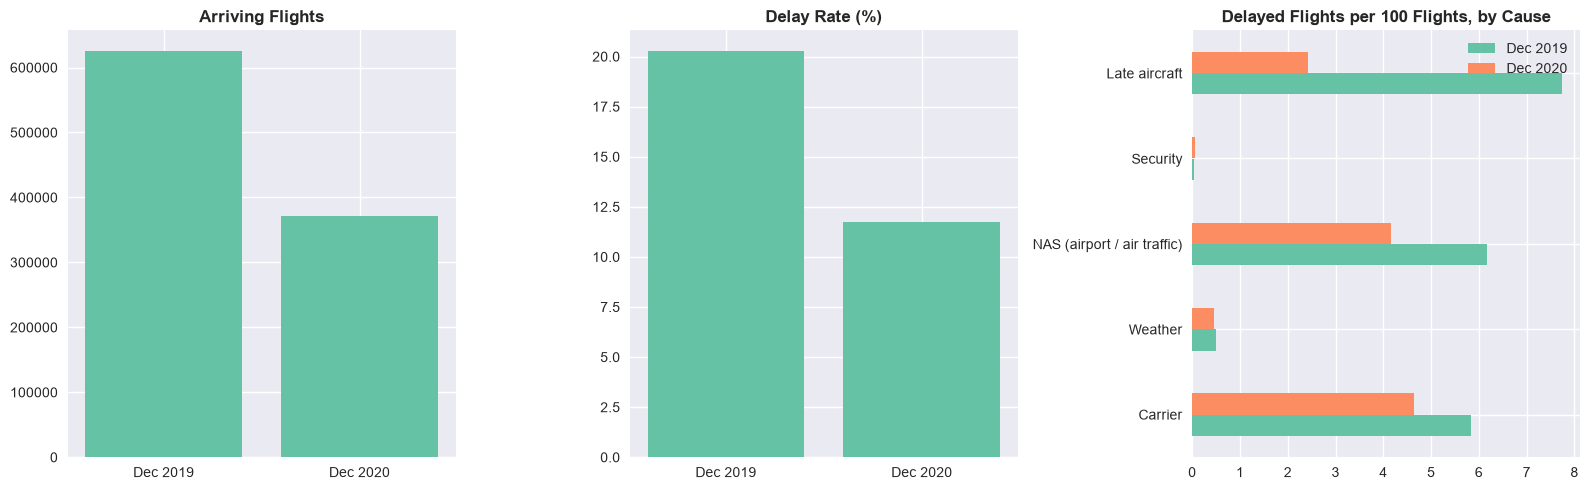

In [88]:
covid = group_rate(df, "year")
covid["diversion_rate"] = df.groupby("year")["arr_diverted"].sum() / covid["flights"] * 100
display(covid[["flights", "delay_rate", "cancel_rate", "diversion_rate"]].round(2))
print("Change in flights: %.1f%%" % ((covid.loc[2020, "flights"] / covid.loc[2019, "flights"] - 1) * 100))

# Delays per 100 flights, by cause
per100 = df.groupby("year")[cause_counts].sum().div(df.groupby("year")["arr_flights"].sum(), axis=0) * 100
per100.columns = labels
display(per100.T.round(2))

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
axes[0].bar(["Dec 2019", "Dec 2020"], covid["flights"])
axes[0].set_title("Arriving Flights", fontweight="bold")

axes[1].bar(["Dec 2019", "Dec 2020"], covid["delay_rate"])
axes[1].set_title("Delay Rate (%)", fontweight="bold")

per100.T.plot(kind="barh", ax=axes[2])
axes[2].set_title("Delayed Flights per 100 Flights, by Cause", fontweight="bold")
axes[2].legend(["Dec 2019", "Dec 2020"])

plt.tight_layout()
plt.show()

**Interpretation**
- Flights fell by about **41%** (625,763 to 371,357) and the delay rate fell from **20.3% to 11.7%**.
- The biggest improvement was in **late-aircraft delays** (7.7 to 2.4 per 100 flights, which is about 62% of the total drop). With fewer flights, planes had more spare time between trips, so one late arrival was less likely to cause the next delay. NAS delays (airport and air traffic congestion) also fell.
- **Cancellations did not improve** (0.93% to 1.04%) even with fewer flights, since schedules were being cut and changed at short notice during the pandemic.
- **Takeaway:** fewer flights and more slack in the schedule means fewer cascading delays.

### Correlation Analysis

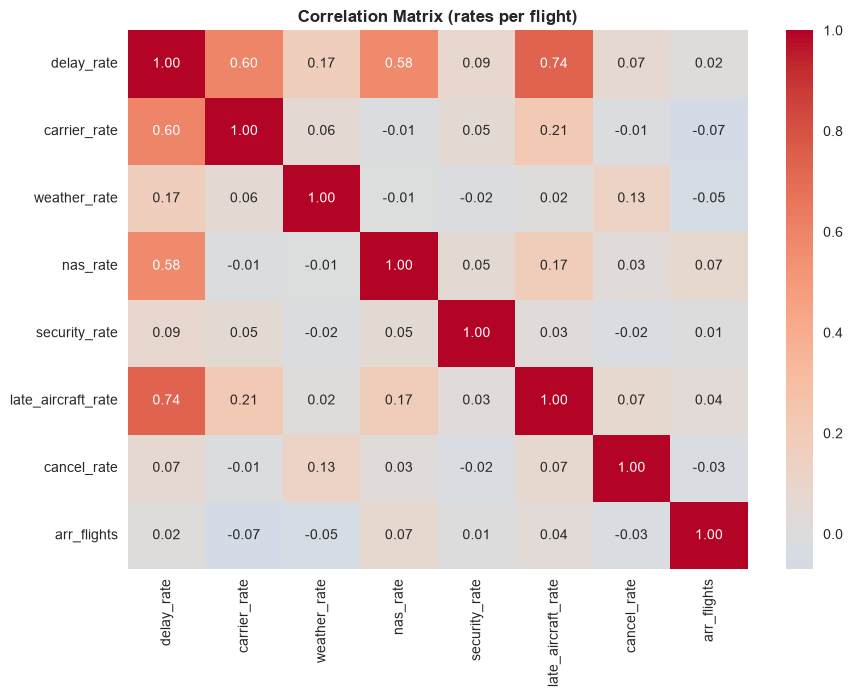

In [89]:
corr_data = df[df["arr_flights"] >= 25].copy()
for name, col in zip(["carrier", "weather", "nas", "security", "late_aircraft"], cause_counts):
    corr_data[name + "_rate"] = corr_data[col] / corr_data["arr_flights"] * 100

corr_cols = ["delay_rate", "carrier_rate", "weather_rate", "nas_rate", "security_rate",
             "late_aircraft_rate", "cancel_rate", "arr_flights"]

plt.figure(figsize=(10, 7))
sns.heatmap(corr_data[corr_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f", center=0)
plt.title("Correlation Matrix (rates per flight)", fontweight="bold")
plt.show()

**Interpretation**
- The delay rate is most strongly linked to the **late-aircraft rate (0.74), carrier rate (0.60) and NAS rate (0.58)**. Weather (0.17) and security (0.09) have weak links.
- Part of this is built in: the cause rates add up to the delay rate, so they have to move together. What is useful is the *ranking*: late aircraft matters most.
- **Cancellation rate** is almost unrelated to delay rate (0.07), so they appear to be separate problems.
- **Number of flights** has almost no correlation with the delay rate. Busier airline–airport pairs aren't much more delayed than smaller ones.
- I used rates instead of raw minutes and counts because raw totals are all correlated with each other simply because bigger operations have more of everything.

### Machine Learning: Predicting Delay Rates

In [97]:
features = [
    'arr_flights',
    'carrier_delay',
    'weather_delay',
    'nas_delay',
    'security_delay',
    'late_aircraft_delay',
    'arr_cancelled',
    'arr_diverted']

X = df[features]
y = df['delay_rate']

# Train-test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

# Random forest model 
rf = RandomForestRegressor(n_estimators=300, max_depth=10, random_state=42)

rf.fit(X_train, y_train)

# Predictions 
predictions = rf.predict(X_test)

# Evaluation
mae = mean_absolute_error(y_test, predictions)

rmse = np.sqrt(mean_squared_error(y_test, predictions))

r2 = r2_score(y_test, predictions)

# Baseline: always predict the training average
baseline = np.full(len(y_test), y_train.mean())

results = pd.DataFrame({
    "MAE":  [mean_absolute_error(y_test, baseline), mean_absolute_error(y_test, predictions)],
    "RMSE": [np.sqrt(mean_squared_error(y_test, baseline)), np.sqrt(mean_squared_error(y_test, predictions))],
    "R²":   [r2_score(y_test, baseline), r2_score(y_test, predictions)],
}, index=["Baseline (always predict the average)", "Random Forest"])

display(results.round(2))

,MAE,RMSE,R²
Baseline (always predict the average),7.80,10.53,-0.00
Random Forest,3.27,5.03,0.77


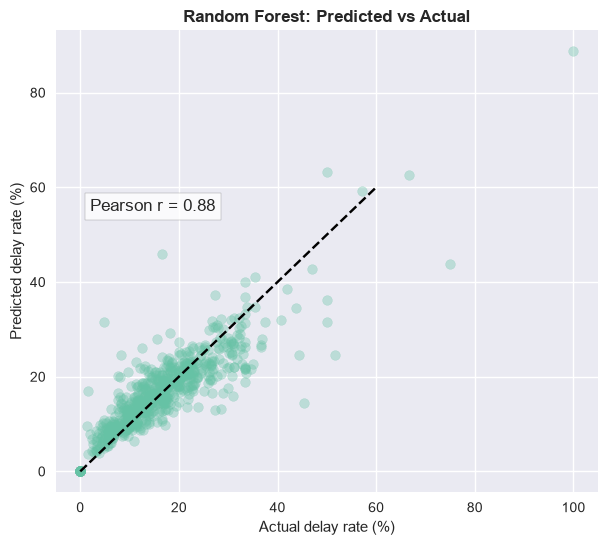

Pearson correlation (r): 0.879
p-value: 1.367e-216


In [101]:
from scipy.stats import pearsonr

# Pearson correlation between actual and predicted values
r, p_value = pearsonr(y_test, predictions)

plt.figure(figsize=(7, 6))
plt.scatter(y_test, predictions, alpha=0.35)
plt.plot([0, 60], [0, 60], "k--")
plt.xlabel("Actual delay rate (%)")
plt.ylabel("Predicted delay rate (%)")
plt.title("Random Forest: Predicted vs Actual", fontweight="bold")

# Show the correlation on the chart
plt.text(2, 55, f"Pearson r = {r:.2f}", fontsize=12,
         bbox=dict(facecolor="white", edgecolor="grey", alpha=0.8))
plt.show()

print(f"Pearson correlation (r): {r:.3f}")
print(f"p-value: {p_value:.4g}")

**Interpretation**
- The model's **R² is about 0.77** and its average error (MAE) is about **3.3 percentage points**, compared to an R² of 0 and an error of 7.8 points for just guessing the average.
- Moreover, the Pearson r is roughly **0.88**, which indicates that the predicted and actual delay rates have a strong positive linear relationship. 

### Conclusions and Recommendations

**What causes delays?**
- About 72% of delay minutes come from **late aircraft and airline-controlled issues**, so most delays are operational and could be reduced with better planning.
- Delays **cascade**: when there were far fewer flights in December 2020, the late-aircraft delays dropped the most.

**How do they vary?**
- **Airlines:** JetBlue had the highest delay rate in both years. Hawaiian and Delta were among the best in 2019.
- **Airports:** Northeast hubs and San Francisco were worst in December 2019, but rankings changed a lot in 2020.

**Recommendations**
1. **Add buffer time between flights** for aircraft with tight schedules, since late-aircraft delay is the biggest cause.
2. **Focus on each airline's main cause:** crew, maintenance and ground operations for airlines with many carrier delays; schedule design for those with many late-aircraft delays.
3. **Compare airlines and airports using weighted delay rates** so small operations don't distort the results.
4. **Collect more data** before using a model to forecast delays.